# Prime Video reviews – data cleaning

This notebook turns the raw Google Play reviews into four files:

| File | Content | Used for |
| --- | --- | --- |
| `prime_reviews_ratings.csv` | every review from the chosen years | star ratings |
| `prime_reviews_clean_full.csv` | every clean English review | text analysis |
| `prime_reviews_to_annotate.csv` | clean English reviews with 10 or more words, without duplicates | annotation set |
| `prime_sample_to_annotate.csv` | random sample of the annotation set (same number per year) | automatic annotation |

Every step follows the same pattern: **why** the step is needed, **look** at the data, **decide and apply**, then **check** what was removed.

## 0. Setup

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import words
from fast_langdetect import detect

pd.set_option('display.max_colwidth', 120)

In [60]:
FILE_PATH = './prime_reviews_raw.csv'
APP_NAME = 'prime'
YEARS_TO_KEEP = [2022, 2023, 2026]

MIN_REAL_WORD_RATIO = 0.6     # dictionary check (section 5b)
MIN_WORDS = 10                # annotation set (section 8)

SAMPLE_SIZE = 5000            # per app -> 10,000 reviews in total for both apps
HAND_SIZE = 50                                        # per app -> 100 reviews to annotate by hand
HAND_FILE = f'{APP_NAME}_human_annotation.xlsx'
RANDOM_SEED = 42

### Helpers
`log_step` records how many reviews are left after each step, overall and per year.
`show_removed` prints how many reviews a step removed and shows a random sample of them, so every cut can be checked by eye.

In [11]:
cleaning_log = []
year_log = []

def log_step(step_name, data):
    cleaning_log.append((step_name, len(data)))
    year_log.append(data['year'].value_counts().sort_index().rename(step_name))
    print(f"{step_name}: {len(data):,} reviews left")

def show_removed(before, after, n=10):
    removed = before[~before['reviewId'].isin(after['reviewId'])]
    print(f"Removed: {len(removed):,} reviews ({len(removed) / len(before) * 100:.1f}%)")
    if len(removed) > 0:
        return removed[['content', 'score', 'year']].sample(min(n, len(removed)), random_state=1)

## 1. First look at the raw data
**Why:** before cleaning, we need to know what the file contains: which columns, how many missing values, and which years the reviews cover.

In [12]:
df_raw = pd.read_csv(FILE_PATH)
print(df_raw.shape)
df_raw.head(3)

(306882, 13)


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,app,extracted_on
0,a93fb51e-e38a-4717-badc-51eb5216884a,Hema Selenator,https://play-lh.googleusercontent.com/a-/ALV-UjXPDvWhmNNB6aOo2yZcQpBkg45vYDgqLtFgtM6bHFvI0FXP2soT,why the heck I have to watch ads for every 5 min while watching a series? irritating asf! you're gonna lose a bunch ...,1,0,3.0.481.2847,2026-11-25 08:02:04,NaN,NaN,3.0.481.2847,prime,2026-11-26
1,4db25d7f-5321-4ac0-9cf8-002a8854621b,Ronald Moore,https://play-lh.googleusercontent.com/a-/ALV-UjXrI5Dl7-c5XTYEesoPjKN5Jg7A2sEDntC6E1AdcZkR11OSApGu,sucks to many commercials,1,0,3.0.482.2147,2026-11-25 06:43:51,NaN,NaN,3.0.482.2147,prime,2026-11-26
2,89991f4a-a76d-4d40-b081-c3c937691025,shakti life,https://play-lh.googleusercontent.com/a-/ALV-UjXokZuKV_5fl6mpxA0-5Ja8Of21d71sTEKRUO_RmcDcpCqaIyBXyg,Not without consent please!!,1,0,3.0.481.2847,2026-11-25 06:24:03,NaN,NaN,3.0.481.2847,prime,2026-11-26


In [13]:
print(df_raw.isna().sum())

reviewId                     0
userName                     2
userImage                    0
content                     22
score                        0
thumbsUpCount                0
reviewCreatedVersion     48471
at                           0
replyContent            306882
repliedAt               306882
appVersion               48471
app                          0
extracted_on                 0
dtype: int64


In [14]:
df_raw['at'] = pd.to_datetime(df_raw['at'], errors='coerce')
df_raw['year'] = df_raw['at'].dt.year
print("First review:", df_raw['at'].min())
print("Last review: ", df_raw['at'].max())

First review: 2022-01-01 00:13:51
Last review:  2026-11-25 08:55:26


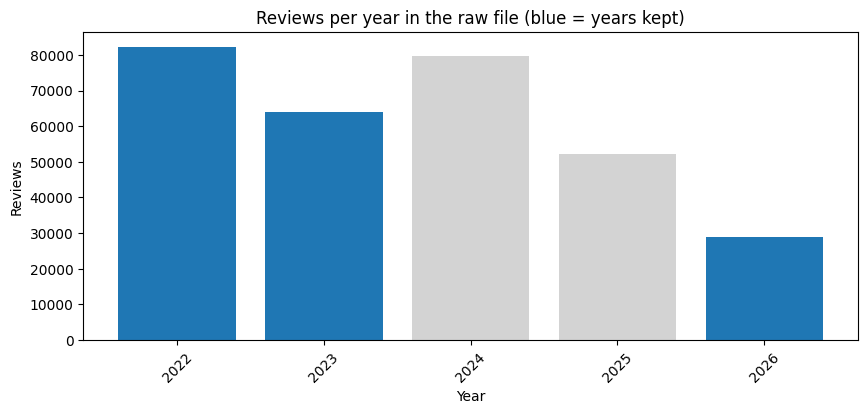

In [15]:
reviews_per_year = df_raw['year'].value_counts().sort_index()
bar_colors = ['tab:blue' if year in YEARS_TO_KEEP else 'lightgrey' for year in reviews_per_year.index]

plt.figure(figsize=(10, 4))
plt.bar(reviews_per_year.index.astype(str), reviews_per_year.values, color=bar_colors)
plt.title('Reviews per year in the raw file (blue = years kept)')
plt.xlabel('Year')
plt.ylabel('Reviews')
plt.xticks(rotation=45)
plt.show()

**What we see:** the file covers several years. The project compares a fixed set of years, so the next step keeps only those.
The last year in the file is not complete (see the last review date above), so for that year averages and shares can be compared, raw counts cannot.

## 2. Keep the project years - ratings set
**Why:** the research question compares the years set by the project. Reviews from other years are not part of the comparison.

We keep only the columns we need: the review id, text, star rating, likes and date. User names, profile pictures and app versions say nothing about consumer value, and user names are personal data we do not need.

In [16]:
columns_to_keep = ['reviewId', 'content', 'score', 'thumbsUpCount', 'at', 'year']
df = df_raw.loc[df_raw['year'].isin(YEARS_TO_KEEP), columns_to_keep].copy()
df['app'] = APP_NAME

log_step('Years kept', df)
df['year'].value_counts().sort_index()

Years kept: 175,166 reviews left


year
2022    82329
2023    64035
2026    28802
Name: count, dtype: int64

**Decision:** the ratings set is saved here, before any text filter.
A star rating is valid whatever the review text says or which language it is written in, so star ratings are always counted on all reviews from the chosen years.

In [17]:
df_ratings = df[['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'at']].copy()
df_ratings.to_csv(f'{APP_NAME}_reviews_ratings.csv', index=False)
print("Saved ratings set:", len(df_ratings))

Saved ratings set: 175166


In [18]:
ratings_per_year = df_ratings.groupby('year')['score'].agg(['count', 'mean']).round(2)
ratings_per_year.columns = ['reviews', 'average_stars']
ratings_per_year

,reviews,average_stars
year,,
2022,82329,3.46
2023,64035,3.34
2026,28802,2.66


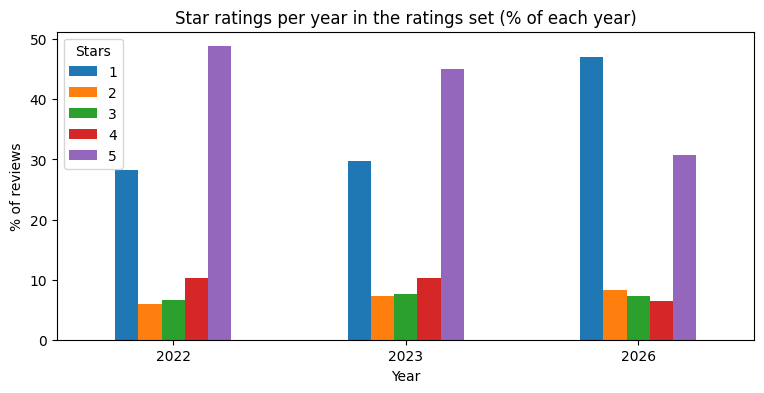

In [19]:
star_share_per_year = pd.crosstab(df_ratings['year'], df_ratings['score'], normalize='index').mul(100).round(1)
star_share_per_year.plot(kind='bar', figsize=(9, 4))
plt.title('Star ratings per year in the ratings set (% of each year)')
plt.xlabel('Year')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.legend(title='Stars')
plt.show()

## 3. Remove reviews with no text
**Why:** a review without words cannot be read or annotated. Its star rating is already kept in the ratings set.

In [20]:
print("Reviews with no text:", df['content'].isna().sum())

Reviews with no text: 16


In [22]:
df_before = df.copy()
df = df.dropna(subset=['content'])
df['content'] = df['content'].astype(str)
log_step('No missing text', df)

No missing text: 175,150 reviews left


## 4. Clean the text
**Why:** to count words and check the language, the text must be in one simple form.
We work on a copy (`content_clean`). The original `content` stays untouched, so the annotator always reads what the user really wrote.

### 4a. Lowercase
**Why:** "Great" and "great" should count as the same word.

In [23]:
df['content_clean'] = df['content'].str.lower()
df[['content', 'content_clean']].sample(5, random_state=1)

,content,content_clean
68804,sbse ghatiya hai ye application. isme download ke bad kv chalta hai kv nhi chalta hai isme recharge Krna hai sb se b...,sbse ghatiya hai ye application. isme download ke bad kv chalta hai kv nhi chalta hai isme recharge krna hai sb se b...
303995,"I have purchase 459for3month but my tv isn't start,pls solve my problem .amozon prime video","i have purchase 459for3month but my tv isn't start,pls solve my problem .amozon prime video"
191785,i got happy.😉,i got happy.😉
269762,Great app,great app
168961,"Bad Azz, Great 👍🏿","bad azz, great 👍🏿"


### 4b. Remove emojis, symbols and punctuation
**Why:** word counts and the dictionary check work on words only. Emojis, symbols and punctuation are replaced by a space, so words that were glued to them stay separate.
Apostrophes inside words are kept ("can't" is not "can"); quote marks around words are removed.

In [24]:
has_symbols = df['content_clean'].str.contains(r"[^a-z0-9\s']", regex=True)
print(f"Reviews with emojis, symbols or punctuation: {has_symbols.sum():,} ({has_symbols.mean() * 100:.1f}%)")

# most common characters that will be removed
removed_characters = df['content_clean'].str.findall(r"[^a-z0-9\s']").explode().dropna()
removed_characters.value_counts().head(20)

Reviews with emojis, symbols or punctuation: 93,919 (53.6%)


content_clean
.    186536
,     57488
!     26633
?     10464
-      5398
👍      5383
"      4970
/      3836
️      3052
)      2917
(      2708
😡      2368
❤      2155
&      2145
👎      1750
👌      1749
:      1608
ा      1353
*      1152
े      1136
Name: count, dtype: int64

In [25]:
df['content_clean'] = df['content_clean'].str.replace(r"[^a-z0-9\s']+", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r"(?<![a-z0-9])'+|'+(?![a-z0-9])", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()

df.loc[has_symbols, ['content', 'content_clean']].sample(min(10, has_symbols.sum()), random_state=1)

,content,content_clean
92279,"Time and again, regardless the excellent WiFi, a really horrible streaming experience! Multiple lags with unbearable...",time and again regardless the excellent wifi a really horrible streaming experience multiple lags with unbearable di...
11334,amazon prime takes a chance I mean give 2-3 days free trial for experience many peoples install tha application and ...,amazon prime takes a chance i mean give 2 3 days free trial for experience many peoples install tha application and ...
147946,App seems to run slow but works good enough.,app seems to run slow but works good enough
126230,Really sub optimal parental controls with no ability to block certain content creators. Also performs dismally with ...,really sub optimal parental controls with no ability to block certain content creators also performs dismally with c...
302272,Awesome shows.,awesome shows
125620,"When we have subscribed once, why do Amazon show many movies separately on rent. This thing on prime video I don't like",when we have subscribed once why do amazon show many movies separately on rent this thing on prime video i don't like
72505,"Not enough free movies, TV shows are not worth watching and boring.",not enough free movies tv shows are not worth watching and boring
84509,I've called & messaged with Amazon. This app sucks! It glitches & the screen freezes. Used to be amazing but sucks 💯...,i've called messaged with amazon this app sucks it glitches the screen freezes used to be amazing but sucks now 2023...
276091,"Absolutely love this app, has a very huge selection of everything especially if you are a prime member.",absolutely love this app has a very huge selection of everything especially if you are a prime member
3772,"I just installed it on my phone and it says to go to settings to change my account's home region, which I need to do...",i just installed it on my phone and it says to go to settings to change my account's home region which i need to do ...


### 4c. Keep numbers
**Why:** numbers often carry meaning in these reviews: prices ("15 dollars"), years, "4k", episode numbers. They are kept in `content_clean`, so the annotation can use them.
They are **not** counted as English or non-English in the dictionary check (section 5b), so they do not change whether a review looks English.

In [26]:
number_tokens = df['content_clean'].str.findall(r"\S*\d\S*").explode().dropna()
has_numbers = df['content_clean'].str.contains(r"\d", regex=True)
print(f"Reviews with a number: {has_numbers.sum():,} ({has_numbers.mean() * 100:.1f}%)")
print("Most common number tokens:")
number_tokens.value_counts().head(20)

Reviews with a number: 16,719 (9.5%)
Most common number tokens:


content_clean
1       2815
2       2547
5       2372
3       1850
10      1326
4       1169
30       704
6        479
20       465
7        459
0        456
4k       356
99       352
1499     351
8        349
15       339
100      327
1500     284
9        274
2022     221
Name: count, dtype: int64

### 4d. Remove reviews with no real word left
**Why:** after cleaning, some reviews are empty or only single letters or numbers (they were only emojis, numbers or symbols). They have nothing to read or annotate.
A review must contain at least one word of two or more letters.

In [27]:
df_before = df.copy()
df = df[df['content_clean'].str.contains(r'[a-z]{2,}', regex=True)].copy()
log_step('Has a real word', df)
show_removed(df_before, df)

Has a real word: 172,035 reviews left
Removed: 3,115 reviews (1.8%)


,content,score,year
277877,♥️,5,2022
70915,🗑🗑🗑,1,2023
181531,❤️,4,2022
145625,👍👍👍👍👍,3,2023
95509,कृष्णा जी का अपमान किया,1,2022
104964,😡😡😡,1,2022
181422,😘,4,2022
155964,👿,4,2026
285054,🤘🤘🤘🤘🤘🤘,5,2022
252913,👍,5,2023


## 5. Keep English reviews
**Why:** the annotation and the word checks are in English. Two checks are used:
- **5a. Language detector:** removes reviews written in another language.
- **5b. Dictionary check:** removes gibberish and other-language text the detector missed.

### 5a. Language detector
The language is detected on the **original** text, because punctuation and full sentences help the detector.

In [28]:
def detect_language(text):
    try:
        result = detect(text.replace('\n', ' '), model='auto', k=1)
        return result[0]['lang']
    except Exception:
        return 'unknown'

df['language'] = df['content'].apply(detect_language)
language_counts = df['language'].value_counts()
print(f"Detected as English: {(df['language'] == 'en').sum():,} ({(df['language'] == 'en').mean() * 100:.1f}%)")
language_counts.head(15)

Detected as English: 162,753 (94.6%)


language
en     162753
it       1322
es        978
de        914
fr        808
pt        591
id        578
nl        536
sv        248
ru        234
ja        228
hu        227
ceb       180
pl        165
fi        148
Name: count, dtype: int64

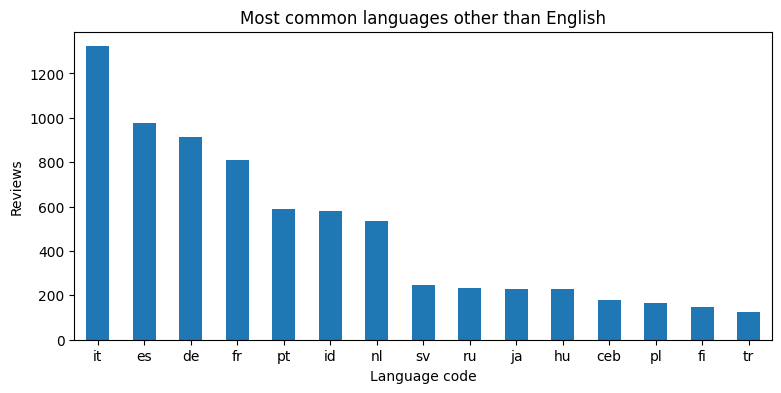

In [29]:
plt.figure(figsize=(9, 4))
language_counts.drop('en', errors='ignore').head(15).plot(kind='bar')
plt.title('Most common languages other than English')
plt.xlabel('Language code')
plt.ylabel('Reviews')
plt.xticks(rotation=0)
plt.show()

In [30]:
# examples of reviews detected as another language
not_english = df[df['language'] != 'en']
not_english_words = not_english['content_clean'].str.split().str.len()

print(f"Non-English reviews with fewer than 3 words: {(not_english_words < 3).sum():,} of {len(not_english):,}")
not_english.loc[not_english_words < 3, ['content', 'language']].sample(min(15, (not_english_words < 3).sum()), random_state=1)

Non-English reviews with fewer than 3 words: 5,949 of 9,282


,content,language
298640,Ok,it
303210,Acha hai,it
186351,supar,ro
146836,Ew d,ku
302610,Masaledar,sv
262350,Nice 👍,fr
262653,super Verygood,fr
182071,Manoj,eo
248087,Excellent 👍🏻👍🏻👍🏻👍🏻👌👌👌👌👌,si
241164,love it!!,ja


In [31]:
print(f"Non-English reviews with 3 or more words: {(not_english_words >= 3).sum():,} of {len(not_english):,}")
not_english.loc[not_english_words >= 3, ['content', 'language']].sample(min(15, (not_english_words >= 3).sum()), random_state=1)

Non-English reviews with 3 or more words: 3,333 of 9,282


,content,language
185827,dekhte rah jao,tr
74271,Ek saal ke subscription k baad isme kuch bhi dekhne layak nhi h jo bhi achi movie hogi vo ya to rent pe hogi ya kisi...,ms
123919,"Peliculas interesantes pero la mayoria estan en Ingles , como para que estan tambien en Espanol",es
93339,Saya berlangganan prime video krn bundling paket internet dr telkomsel. Yg sebelumnya bundling sama disney. Entah kn...,ms
71800,Sala etana bekar game,id
176136,Nice data optimisation,fr
110026,Non serious app,it
174260,Laptop par bhi start honi chahiye ESI recharge me,fr
3692,bakvass hai koni na khari de nhi download kre,io
251159,Muy buenas series y películas,es


In [32]:
df_before = df.copy()
df = df[df['language'] == 'en'].copy()
log_step('English (detector)', df)
show_removed(df_before, df)

English (detector): 162,753 reviews left
Removed: 9,282 reviews (5.4%)


,content,score,year
105819,Ee bokkalo appki 500₹ kattadameh ekkuva malli 1500₹ anta yearki velli...... Panikimalina business statistics vadamka...,1,2022
104108,bad habits,1,2022
280960,Great!!!,5,2022
108749,"f,bg",2,2026
149802,Add More Content سالوں کوئ وی کم دی فلم نہیں لبھدی پنجابی,3,2023
181583,Great.,4,2022
278072,Ok,5,2022
300374,Gucci,5,2022
279600,Yea boys,5,2022
297869,Jko,5,2022


### 5b. Dictionary check
**Why:** some reviews pass the detector but are not readable English: gibberish ("eww ee ww"), names, or other languages written in Latin letters.
For each review we compute the share of its words that are English words. Numbers are left out of this count. A review is kept if at least `MIN_REAL_WORD_RATIO` of its words are real words.

**A strict dictionary is not enough.** The NLTK word list misses many normal forms ("crashing", "discontinued") and app words ("netflix", "subscription"). So a word also counts as real if:
- it contains an apostrophe (contractions like "don't", "it's");
- it is an app or streaming word from our list;
- it is a dictionary word plus a common ending (-s, -es, -d, -ed, -ing, -ly, -er), also with a doubled letter ("stopped" → "stop").

In [33]:
nltk.download('words', quiet=True)
english_vocab = set(w.lower() for w in words.words())
app_words = {'netflix', 'amazon', 'prime', 'app', 'apps', 'tv','ads',  'adverts', 'advt',
             'subscription', 'subscriptions', 'streaming', 'login', 'logout', 'wifi',
             'chromecast', 'android', 'iphone', 'ipad', 'hd', 'overpriced', 'cancelled', 'canceled'}
english_vocab = english_vocab | app_words

def is_dictionary_word(word):
    return word in english_vocab

def is_real_word(word):
    if "'" in word or word in english_vocab:
        return True
    for ending in ['s', 'es', 'd', 'ed', 'ing', 'ly', 'er']:
        if word.endswith(ending):
            base = word[:-len(ending)]
            if len(base) >= 3 and (base in english_vocab or base[:-1] in english_vocab):
                return True
    return False

def real_word_ratio(text, word_check):
    tokens = [w for w in text.split() if not any(ch.isdigit() for ch in w)]   # numbers are not counted
    if len(tokens) == 0:
        return 0
    return sum(1 for w in tokens if word_check(w)) / len(tokens)

df['strict_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_dictionary_word))
df['real_word_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_real_word))
df['real_word_ratio'].describe()

count    162753.000000
mean          0.950169
std           0.137500
min           0.000000
25%           0.960000
50%           1.000000
75%           1.000000
max           1.000000
Name: real_word_ratio, dtype: float64

**Choosing the threshold:** first we look at the distribution and at what each candidate threshold would remove, then we choose.

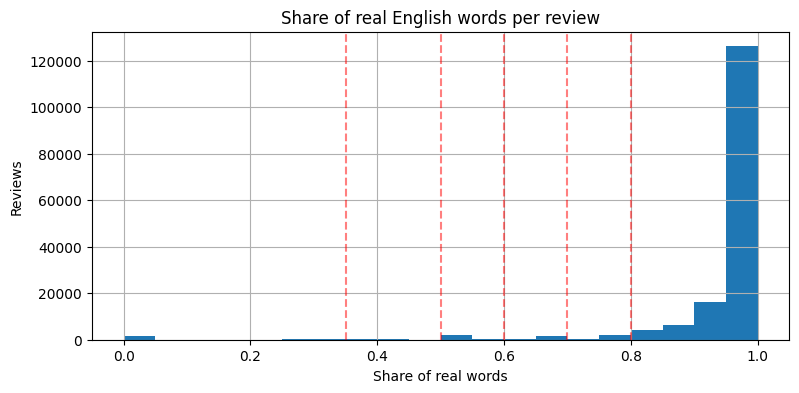

In [36]:
CANDIDATES = [0.35, 0.5, 0.6, 0.7, 0.8]

plt.figure(figsize=(9, 4))
df['real_word_ratio'].hist(bins=20)
for threshold in CANDIDATES:
    plt.axvline(threshold, linestyle='--', color='red', alpha=0.5)
plt.title('Share of real English words per review')
plt.xlabel('Share of real words')
plt.ylabel('Reviews')
plt.show()

In [37]:
for threshold in CANDIDATES:
    removed = (df['real_word_ratio'] < threshold).sum()
    print(f"Threshold {threshold}: removes {removed:,} reviews ({removed / len(df) * 100:.1f}%)")

Threshold 0.35: removes 2,251 reviews (1.4%)
Threshold 0.5: removes 2,672 reviews (1.6%)
Threshold 0.6: removes 5,007 reviews (3.1%)
Threshold 0.7: removes 7,102 reviews (4.4%)
Threshold 0.8: removes 9,712 reviews (6.0%)


**Reading examples in each band:** which reviews would each threshold remove?

In [38]:
bands = [(0, 0.35), (0.35, 0.5), (0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 1.0)]
for low, high in bands:
    band = df[(df['real_word_ratio'] >= low) & (df['real_word_ratio'] < high)]
    print(f"--- share of real words {low}–{high}: {len(band):,} reviews ---")
    print(band['content'].sample(min(10, len(band)), random_state=1).to_string(index=False))
    print()

--- share of real words 0–0.35: 2,251 reviews ---
                   .. Bl❤️🙌🏻🐛00000l
                                Osm
                       IInteresting
                          RAJUKUMAR
                             Deepak
                           Mirzapur
                             Bakwas
                     Surendra Kumar
Kannada yake illa nimdu yakri video
                                Osm

--- share of real words 0.35–0.5: 421 reviews ---
                          A mla ml ml a a ml a mm a mp ma ml mm mm m a mm ma ml a ml ammmm ML ml N NM ml ML ml nmmm on m
Isse to accha YouTube hai. Ye app to fasa rahe hai. Amazon prime video bilkul bhi download na kare. Ye app bahot bada...
very poor service item dikhate kaya hai bhejte kaya hai koi complaint karne ka platform bhi nahi hai koi sunvai bhi n...
                                                   Gahtiya hote ja rahi saare saaman costly or faltu k delivery expenses
      sabse ghatiya app h , har din koi series dekho to

**Words not recognised in each band:** helps to see whether the removed reviews are really not English, or only use words missing from the dictionary (which could be added to `app_words`).

In [39]:
for low, high in bands[:-1]:
    band = df[(df['real_word_ratio'] >= low) & (df['real_word_ratio'] < high)]
    unknown = band['content_clean'].str.split().explode()
    unknown = unknown[~unknown.str.contains(r'\d') & ~unknown.apply(is_real_word)]
    print(f"--- {low}–{high}: most common unrecognised words ---")
    print(unknown.value_counts().head(15).to_dict())
    print()

--- 0–0.35: most common unrecognised words ---
{'hai': 193, 'osm': 109, 'bakwas': 62, 'aap': 44, 'cc': 41, 'ghatiya': 38, 'nic': 35, 'mm': 34, 'download': 32, 'bhi': 32, 'ss': 32, 'nhi': 32, 'bhai': 31, 'bekar': 29, 'ke': 28}

--- 0.35–0.5: most common unrecognised words ---
{'hai': 326, 'bhi': 116, 'ke': 115, 'nahi': 63, 'liye': 60, 'nhi': 57, 'ki': 54, 'aur': 53, 'raha': 52, 'ek': 43, 'download': 40, 'kar': 40, 'aap': 37, 'kya': 32, 'mm': 32}

--- 0.5–0.6: most common unrecognised words ---
{'hai': 369, 'aap': 223, 'bhi': 162, 'ke': 126, 'nhi': 105, 'nahi': 98, 'ki': 93, 'download': 71, 'ek': 56, 'liye': 50, 'raha': 47, 'bekar': 46, 'aur': 45, 'kya': 42, 'bakwas': 41}

--- 0.6–0.7: most common unrecognised words ---
{'hai': 167, 'download': 111, 'aap': 97, 'ott': 90, 'bhi': 75, 'ke': 61, 'nhi': 55, 'has': 52, 'ki': 44, 'ui': 38, 'pls': 38, 'nahi': 35, 'otp': 32, 'aur': 27, 'rha': 25}

--- 0.7–0.8: most common unrecognised words ---
{'download': 203, 'has': 161, 'ott': 123, 'hai': 87,

**Strict vs loosened dictionary:** these reviews would be removed with the strict word list but are kept with the loosened one.

In [40]:
brought_back = df[(df['strict_ratio'] < MIN_REAL_WORD_RATIO) & (df['real_word_ratio'] >= MIN_REAL_WORD_RATIO)]
print("Reviews kept thanks to the loosened dictionary:", len(brought_back))
brought_back[['content', 'content_clean']].sample(min(15, len(brought_back)), random_state=1)

Reviews kept thanks to the loosened dictionary: 4309


,content,content_clean
257545,"FANSTASTIC!!! lots of shows, great movies. It stopped shuddering and rebooting finally.",fanstastic lots of shows great movies it stopped shuddering and rebooting finally
123375,Otp not generated,otp not generated
3767,"don't install,🥴",don't install
126713,Crashing frequently,crashing frequently
130812,Channels button disappeared,channels button disappeared
126520,Always has issues with downloaded videos it doesn't work with data off,always has issues with downloaded videos it doesn't work with data off
249987,Good options of shows and movies!,good options of shows and movies
168596,They wants all details is very affencer,they wants all details is very affencer
180876,It's good 👍🏻,it's good
78027,Constantly disconnects. Soo many bugs needs fixing.,constantly disconnects soo many bugs needs fixing


**Decision: MIN_REAL_WORD_RATIO = 0.6.**
- Below 0.6 the examples are mostly gibberish, names or other languages in Latin letters.
- From 0.6 up, the reviews are readable English, sometimes with a few slang or misspelled words.
- A higher threshold (0.7–0.8) would start removing readable reviews with typos or slang.

In [41]:
df_before = df.copy()
df = df[df['real_word_ratio'] >= MIN_REAL_WORD_RATIO].copy()
df = df.drop(columns=['strict_ratio', 'real_word_ratio', 'language'])
log_step('Real English words', df)
show_removed(df_before, df, n=20)

Real English words: 157,746 reviews left
Removed: 5,007 reviews (3.1%)


,content,score,year
278815,Vgood,5,2022
127369,It's okay.,2,2023
180894,Good aap,4,2022
124291,Verey bad,2,2023
106309,Gobar,1,2022
80675,Randi ka app bahot disturb karta hai,1,2023
238182,BADASS APP,5,2023
80454,Amc bf p 0 a,1,2023
294030,Amazing pushpa,5,2022
154991,Minnal murale,3,2022


## 6. Save the full clean set
This set keeps every clean English review. It is used for the text analysis, so it is not reduced any further.

In [42]:
df['word_count'] = df['content_clean'].str.split().str.len()
df['text_repeats'] = df.groupby('content_clean')['reviewId'].transform('count')   # how often the same clean text appears

df_clean_full = df.copy()
df_clean_full.to_csv(f'{APP_NAME}_reviews_clean_full.csv', index=False)
print("Saved full clean set:", len(df_clean_full))

Saved full clean set: 157746


**Check: does the text cleaning change the star ratings?** If the averages per year are close, removing empty, non-English and gibberish reviews does not bias the ratings.

In [43]:
rating_check = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean()}).round(2)
rating_check['difference'] = rating_check['clean_text_set'] - rating_check['ratings_set']
rating_check

,ratings_set,clean_text_set,difference
year,,,
2022,3.46,3.42,-0.04
2023,3.34,3.33,-0.01
2026,2.66,2.62,-0.04


## 7. Repeated texts
**Why check:** many identical reviews could be spam or a coordinated campaign rather than individual opinions. We look at them on the full clean set, **before** the length cut, so short repeated phrases and campaigns are both visible.
Common short phrases ("i love this app") repeat naturally. A campaign looks like one specific message, often off-topic, many times, with all 1 or all 5 stars.

**Decision:** repeated texts are kept in the clean set, because they are real reviews. The column `text_repeats` (how many times the same clean text appears) identifies them, so they can be excluded later in the analysis.

In [44]:
repeated = (df_clean_full[df_clean_full['text_repeats'] >= 5]
            .groupby('content_clean')
            .agg(times=('reviewId', 'count'), words=('word_count', 'first'), average_stars=('score', 'mean'),
                 first_year=('year', 'min'), last_year=('year', 'max'))
            .sort_values('times', ascending=False))
repeated['average_stars'] = repeated['average_stars'].round(2)
print("Texts repeated 5 or more times:", len(repeated))
print("Reviews involved:", repeated['times'].sum())
repeated.head(25)

Texts repeated 5 or more times: 795
Reviews involved: 40819


,times,words,average_stars,first_year,last_year
content_clean,,,,,
good,8420,1,4.61,2022,2026
nice,2756,1,4.65,2022,2026
excellent,2096,1,4.93,2022,2026
awesome,1645,1,4.92,2022,2026
great,1615,1,4.88,2022,2026
love it,1555,2,4.95,2022,2026
very good,1489,2,4.80,2022,2026
super,1203,1,4.75,2022,2026
nice app,799,2,4.70,2022,2026


**Long repeated texts:** a long text written many times is unlikely to be a coincidence; this is where campaigns show up.

In [46]:
repeated[repeated['words'] >= MIN_WORDS]

,times,words,average_stars,first_year,last_year
content_clean,,,,,


**Are short reviews more repeated?** Share of reviews whose exact text appears more than once, by length.

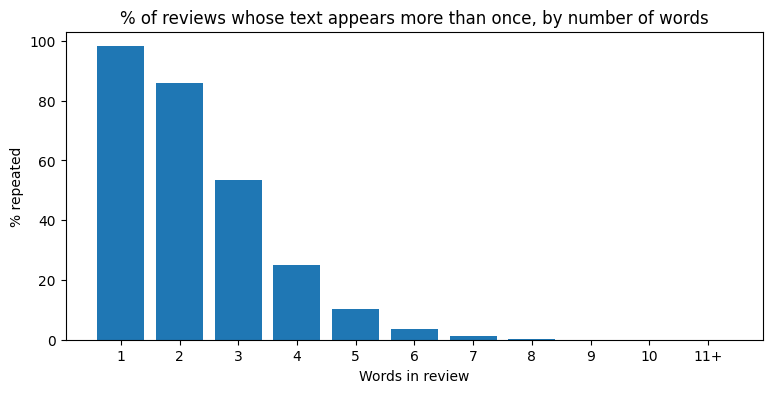

words_group
1      98.2
2      86.1
3      53.4
4      24.9
5      10.2
6       3.5
7       1.1
8       0.3
9       0.0
10      0.0
11+     0.0
Name: text_repeats, dtype: float64

In [47]:
df_clean_full['words_group'] = df_clean_full['word_count'].clip(upper=11)
group_labels = {i: str(i) for i in range(1, 11)}
group_labels[11] = '11+'

repeat_by_length = (df_clean_full['text_repeats'] > 1).groupby(df_clean_full['words_group']).mean().mul(100).round(1)
repeat_by_length.index = repeat_by_length.index.map(group_labels)

plt.figure(figsize=(9, 4))
plt.bar(repeat_by_length.index, repeat_by_length.values)
plt.title('% of reviews whose text appears more than once, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% repeated')
plt.show()
repeat_by_length

## 8. Review length - annotation set
**Why:** the annotation looks for the *reasons* behind satisfaction (price, ads, content, technical problems). The star rating already tells us *how* satisfied a user is.
Very short reviews ("good", "love it") show a feeling but rarely a reason. We look at the data to decide how many words a review needs.

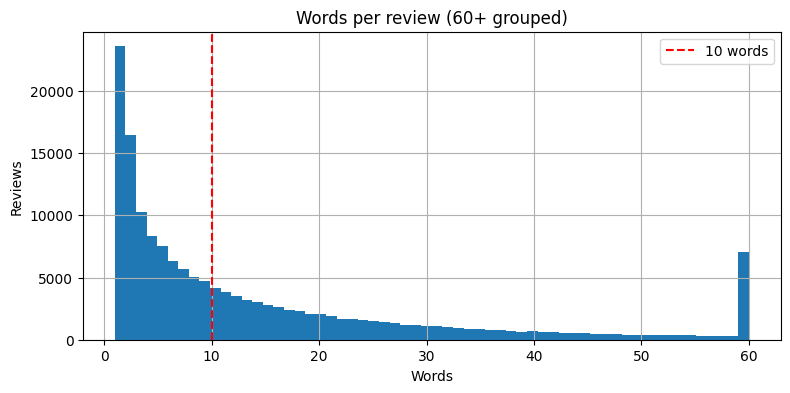

In [48]:
plt.figure(figsize=(9, 4))
df_clean_full['word_count'].clip(upper=60).hist(bins=60)
plt.axvline(MIN_WORDS, color='red', linestyle='--', label=f'{MIN_WORDS} words')
plt.title('Words per review (60+ grouped)')
plt.xlabel('Words')
plt.ylabel('Reviews')
plt.legend()
plt.show()

In [49]:
length_table = df_clean_full.groupby('words_group').agg(
    reviews=('reviewId', 'count'),
    average_stars=('score', 'mean'))
length_table['% of reviews'] = (length_table['reviews'] / len(df_clean_full) * 100).round(1)
length_table['average_stars'] = length_table['average_stars'].round(2)
length_table.index = length_table.index.map(group_labels)
length_table

,reviews,average_stars,% of reviews
words_group,,,
1,23575,4.60,14.9
2,16475,4.30,10.4
3,10293,3.72,6.5
4,8305,3.68,5.3
5,7499,3.51,4.8
6,6298,3.36,4.0
7,5653,3.30,3.6
8,5063,3.17,3.2
9,4714,3.04,3.0


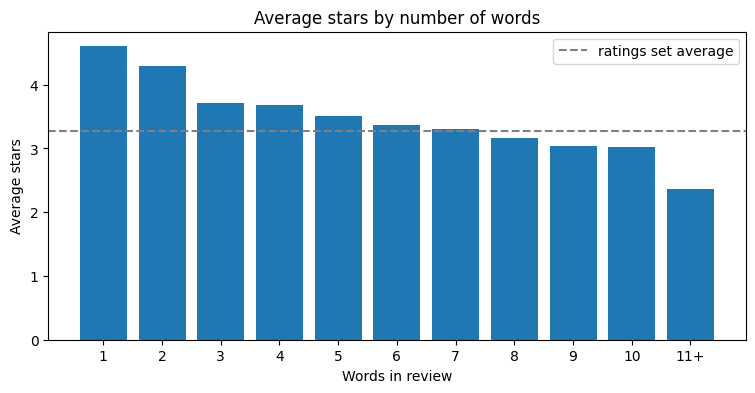

In [50]:
plt.figure(figsize=(9, 4))
plt.bar(length_table.index, length_table['average_stars'])
plt.axhline(df_ratings['score'].mean(), color='grey', linestyle='--', label='ratings set average')
plt.title('Average stars by number of words')
plt.xlabel('Words in review')
plt.ylabel('Average stars')
plt.legend()
plt.show()

**Do short reviews talk about value?** We count reviews that mention a price, ads, subscription or content word, by length.

In [51]:
value_words = (r"\b(price|prices|expensive|cheap|money|cost|costs|pay|paid|paying|worth|subscription|"
               r"rent|rental|ads|ad|advt|advertisement|advertisements|free|fee|charge|charged|membership|content|available)\b")
df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)

value_table = df_clean_full.groupby('words_group')['mentions_value'].agg(['mean', 'sum'])
value_table.columns = ['% mentioning value', 'reviews mentioning value']
value_table['% mentioning value'] = (value_table['% mentioning value'] * 100).round(1)
value_table.index = value_table.index.map(group_labels)
value_table

C:\Users\elesa\AppData\Local\Temp\ipykernel_23140\3853407355.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)


,% mentioning value,reviews mentioning value
words_group,,
1,0.5,108
2,2.6,427
3,7.7,793
4,8.9,743
5,10.8,809
6,13.2,831
7,15.6,880
8,17.5,885
9,19.7,928


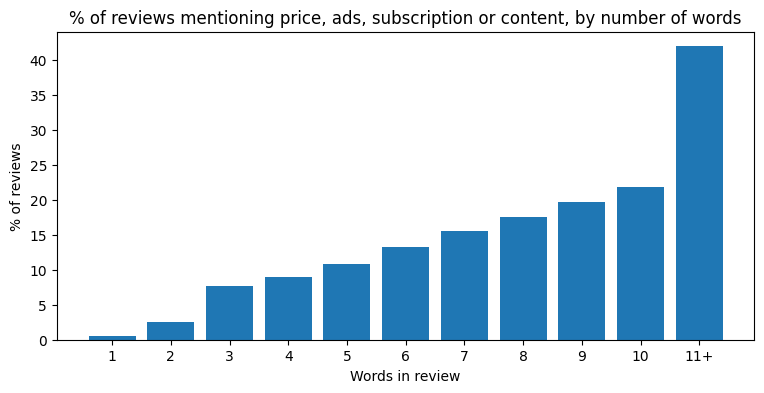

In [52]:
plt.figure(figsize=(9, 4))
plt.bar(value_table.index, value_table['% mentioning value'])
plt.title('% of reviews mentioning price, ads, subscription or content, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% of reviews')
plt.show()

**Reading examples:** do reviews of this length give a reason?

In [53]:
for n_words in [3, 5, 8, 10, 15]:
    print(f"--- {n_words} words ---")
    same_length = df_clean_full[df_clean_full['word_count'] == n_words]['content']
    print(same_length.sample(min(10, len(same_length)), random_state=1).to_string(index=False))
    print()

--- 3 words ---
            easy to activate
                Can't log in
wrost, streaming application
                 It's so nyc
             Easy and great.
               I love it 😍😍😍
                 I love it 😀
          app keeps crashing
           Too much crashing
           Supar my favorite

--- 5 words ---
             Great app, easy to use.
         i always prefer amazon apps
   Very lagggy, too slow application
      Always happy, find good movies
           ads making this app suck.
             one the best ones going
            Does what it's sposed to
        where is Hdr10+ advanced bro
        Comfortable and easy to use.
Keep my information private. please.

--- 8 words ---
           Please realse the ncis season 20 in india
   My favourite out of all the streaming sites !!!!!
App is freezing after the latest update.. annoying 😑
     all south parks via paramount. top notch telly!
   Great for when relaxing always something to watch
        Great selection o

**Comparing cuts:** what each minimum length keeps, and how it changes the stars and the years.

In [54]:
cut_rows = []
for min_words in [3, 5, 8, 10, 15]:
    kept = df_clean_full[df_clean_full['word_count'] >= min_words]
    row = {'minimum words': min_words,
           'reviews kept': len(kept),
           '% kept': round(len(kept) / len(df_clean_full) * 100, 1),
           'average stars': round(kept['score'].mean(), 2),
           '% mentioning value': round(kept['mentions_value'].mean() * 100, 1)}
    for year in YEARS_TO_KEEP:
        row[f'{year} kept'] = (kept['year'] == year).sum()
    cut_rows.append(row)

cut_table = pd.DataFrame(cut_rows)
cut_table

,minimum words,reviews kept,% kept,average stars,% mentioning value,2022 kept,2023 kept,2026 kept
0,3,117696,74.6,2.83,29.2,52263,44033,21400
1,5,99098,62.8,2.67,33.1,43426,37224,18448
2,8,79648,50.5,2.49,38.0,34247,29917,15484
3,10,69871,44.3,2.41,40.7,29826,26196,13849
4,15,52216,33.1,2.24,46.1,21994,19461,10761


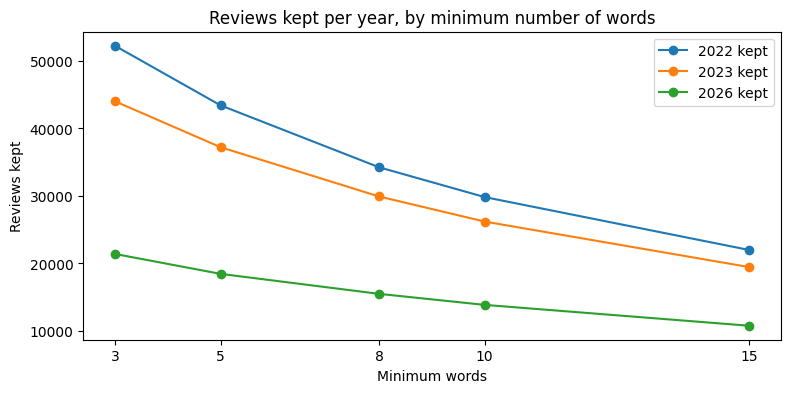

In [55]:
year_columns = [f'{year} kept' for year in YEARS_TO_KEEP]
cut_table.set_index('minimum words')[year_columns].plot(marker='o', figsize=(9, 4))
plt.title('Reviews kept per year, by minimum number of words')
plt.xlabel('Minimum words')
plt.ylabel('Reviews kept')
plt.xticks(cut_table['minimum words'])
plt.show()

**Decision: 10 words or more.**
- Reviews under 10 words are mostly a feeling ("love it", "worst app ever") and rarely say *why*; the share of reviews mentioning price, ads or content grows with length.
- Short reviews are also much more often repeated word for word (section 7), so they add little new information.
- With 10+ words every year still has far more reviews than the sample needs (section 10).
- Any minimum length makes the set more negative, because longer reviews are more often complaints. This is why star ratings are always taken from the ratings set, not from the annotation set.
- Likes are not used: most reviews have none, and likes depend on how long a review has been online.

In [56]:
df_before = df_clean_full.copy()
df_annotate = df_clean_full[df_clean_full['word_count'] >= MIN_WORDS].copy()
log_step(f'{MIN_WORDS}+ words', df_annotate)
show_removed(df_before, df_annotate, n=20)

10+ words: 69,871 reviews left
Removed: 87,875 reviews (55.7%)


,content,score,year
172287,Nice,4,2023
264176,Very entertaining and well presented,5,2023
77541,"Cannot register. I received otp, but cannot register.",1,2023
189596,good,5,2026
278951,Lots of shows,5,2022
297209,Good collection,5,2022
273332,Excellent,5,2022
293017,Keep updating more and more movies.. with every genre ..,5,2022
102240,It even want to install,1,2022
187551,Good quality,5,2026


## 9. Remove duplicates - annotation set
**Why:** the same text gets the same annotation, so annotating it more than once only costs time. Each text is kept once; `text_repeats` says how many reviews it stands for.

! Remember to redistribute the labels back to every review with the same `content_clean` when needed.

In [57]:
df_annotate_unique = df_annotate.drop_duplicates(subset=['content_clean']).copy()
log_step('No duplicates', df_annotate_unique)
show_removed(df_annotate, df_annotate_unique)

No duplicates: 69,864 reviews left
Removed: 7 reviews (0.0%)


,content,score,year
288883,God bless America and Amazon Prime Video ^ Amazon Mobile LLC ^ … bye 🙋‍♀️… 🇵🇭✨🇺🇸 ………†,5,2022
150404,It's unusually difficult to navigate between what's included with Prime and what is only rent or buy. There's a limi...,3,2022
101171,Renting a movie option in prime video is a terrible descision. People buy prime subscriptions because they can steam...,1,2022
8646,"""I purchased an Amazon Prime Video subscription, but contrary to my expectations, I have to watch ads on every movie...",1,2026
186665,"I've been using Prime Video for a while, and it's a great streaming platform with a good selection of movies and ser...",5,2026
151295,Wow! This update has really broken the app. Downloads have audio description on as default (you have to go into the ...,3,2022
276188,Enjoy Amazon Prime Video in over 200 countries and territories around the globe! Download movies and TV shows using ...,5,2022


In [58]:
annotate_cols = ['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'word_count', 'text_repeats', 'content', 'content_clean']
df_annotate_unique[annotate_cols].to_csv(f'{APP_NAME}_reviews_to_annotate.csv', index=False)
print("Saved annotation set:", len(df_annotate_unique))
df_annotate_unique['year'].value_counts().sort_index()

Saved annotation set: 69864


year
2022    29821
2023    26196
2026    13847
Name: count, dtype: int64

## 10. Sample for the automatic annotation
**Why:** annotating the whole annotation set would take many hours, and the comparison between years only needs a large enough sample of each year.
We take **5,000 reviews per app (10,000 in total)**, split **equally between the years**. With the same number of reviews, every year is measured with the same precision (about ±2.4 percentage points with ~1,667 reviews), so differences between years are not caused by different sample sizes.

The reviews we annotated by hand are **left out**: they are the test set used to check the quality of the automatic annotation, so they must not be in the sample the model labels.

In [61]:
per_year_hand = HAND_SIZE // len(YEARS_TO_KEEP)
extra_hand = HAND_SIZE % len(YEARS_TO_KEEP)

hand_parts = []
for i, year in enumerate(YEARS_TO_KEEP):
    n = per_year_hand + (1 if i < extra_hand else 0)
    year_pool = df_annotate_unique[df_annotate_unique['year'] == year]
    hand_parts.append(year_pool.sample(min(n, len(year_pool)), random_state=RANDOM_SEED + 1))

hand = pd.concat(hand_parts).sample(frac=1, random_state=RANDOM_SEED)   # shuffle, so years are mixed
hand = pd.DataFrame({
    'sample_id': range(1, len(hand) + 1),
    'reviewId': hand['reviewId'].values,
    'Service': APP_NAME,
    'Year': hand['year'].values,
    'Stars': hand['score'].values,
    'Words': hand['word_count'].values,
    'Review text': hand['content'].values,
    'content_clean': hand['content_clean'].values,
    'Your label': '',
    'Comment': ''})
hand.to_excel(HAND_FILE, index=False)
print(f"Created {HAND_FILE}: {len(hand)} reviews to annotate by hand")
print(hand['Year'].value_counts().sort_index())

is_hand_labelled = df_annotate_unique['reviewId'].isin(hand['reviewId'])
print(f"Left out of the sample: {is_hand_labelled.sum()}")
sample_pool = df_annotate_unique[~is_hand_labelled]

Created prime_human_annotation.xlsx: 50 reviews to annotate by hand
Year
2022    17
2023    17
2026    16
Name: count, dtype: int64
Left out of the sample: 50


In [62]:
per_year = SAMPLE_SIZE // len(YEARS_TO_KEEP)
extra = SAMPLE_SIZE % len(YEARS_TO_KEEP)      # left-over reviews go to the first years, so the total is exact

samples = []
for i, year in enumerate(YEARS_TO_KEEP):
    n = per_year + (1 if i < extra else 0)
    year_pool = sample_pool[sample_pool['year'] == year]
    if len(year_pool) < n:
        print(f"! {year}: only {len(year_pool):,} reviews available, all are taken")
        n = len(year_pool)
    samples.append(year_pool.sample(n, random_state=RANDOM_SEED))

df_sample = pd.concat(samples)
print(f"Sample: {len(df_sample):,} reviews")
df_sample['year'].value_counts().sort_index()

Sample: 5,000 reviews


year
2022    1667
2023    1667
2026    1666
Name: count, dtype: int64

**Check: is the sample like the annotation set it comes from?** Within each year, the stars and the length should be close, because the sample is random.

In [63]:
sample_check = pd.DataFrame({
    'set_stars': df_annotate_unique.groupby('year')['score'].mean(),
    'sample_stars': df_sample.groupby('year')['score'].mean(),
    'set_median_words': df_annotate_unique.groupby('year')['word_count'].median(),
    'sample_median_words': df_sample.groupby('year')['word_count'].median()}).round(2)
sample_check

,set_stars,sample_stars,set_median_words,sample_median_words
year,,,,
2022,2.52,2.55,22.0,21.0
2023,2.56,2.56,22.0,22.0
2026,1.88,1.89,25.0,24.0


In [64]:
df_sample[annotate_cols].to_csv(f'{APP_NAME}_sample_to_annotate.csv', index=False)
print("Saved sample:", len(df_sample))

Saved sample: 5000


## 11. Summary
### Reviews left after each step

In [65]:
log = pd.DataFrame(cleaning_log, columns=['step', 'rows_left'])
log['removed'] = log['rows_left'].shift(1) - log['rows_left']
log['removed_%_of_previous'] = (log['removed'] / log['rows_left'].shift(1) * 100).round(1)
print("Original file:", len(df_raw))
print(log.to_string(index=False))

Original file: 306882
              step  rows_left  removed  removed_%_of_previous
        Years kept     175166      NaN                    NaN
   No missing text     175150     16.0                    0.0
   No missing text     175150      0.0                    0.0
   Has a real word     172035   3115.0                    1.8
English (detector)     162753   9282.0                    5.4
Real English words     157746   5007.0                    3.1
         10+ words      69871  87875.0                   55.7
     No duplicates      69864      7.0                    0.0


In [66]:
year_table = pd.concat(year_log, axis=1)
year_table

,Years kept,No missing text,No missing text,Has a real word,English (detector),Real English words,10+ words,No duplicates
year,,,,,,,,
2022,82329,82322,82322,80735,76112,73521,29826,29821
2023,64035,64027,64027,62893,59347,57539,26196,26196
2026,28802,28801,28801,28407,27294,26686,13849,13847


In [67]:
# % of each year's reviews still left after each step
year_pct = (year_table.div(year_table['Years kept'], axis=0) * 100).round(1)
year_pct

,Years kept,No missing text,No missing text,Has a real word,English (detector),Real English words,10+ words,No duplicates
year,,,,,,,,
2022,100.0,100.0,100.0,98.1,92.4,89.3,36.2,36.2
2023,100.0,100.0,100.0,98.2,92.7,89.9,40.9,40.9
2026,100.0,100.0,100.0,98.6,94.8,92.7,48.1,48.1


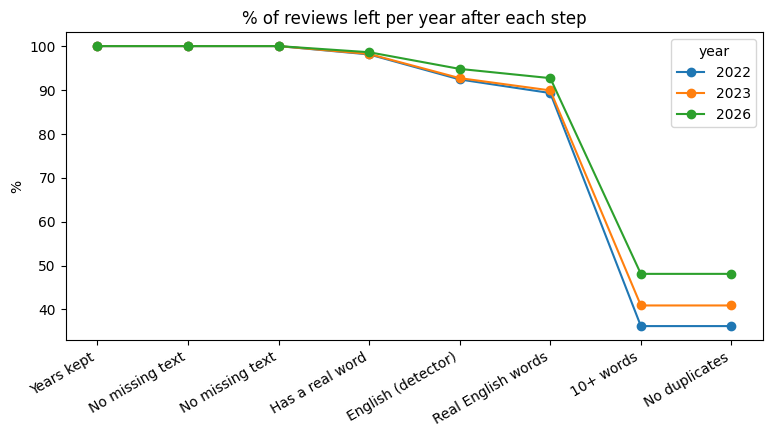

In [68]:
year_pct.T.plot(marker='o', figsize=(9, 4))
plt.title('% of reviews left per year after each step')
plt.ylabel('%')
plt.xticks(range(len(year_pct.columns)), year_pct.columns, rotation=30, ha='right')
plt.show()

### Star ratings in the sets
The ratings set and the clean text set should be close. The annotation set is expected to be more negative, because it keeps longer reviews. The sample should be close to the annotation set.

In [69]:
mean_rating_all = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean(),
    'annotation_set': df_annotate_unique.groupby('year')['score'].mean(),
    'sample': df_sample.groupby('year')['score'].mean()}).round(2)
mean_rating_all

,ratings_set,clean_text_set,annotation_set,sample
year,,,,
2022,3.46,3.42,2.52,2.55
2023,3.34,3.33,2.56,2.56
2026,2.66,2.62,1.88,1.89


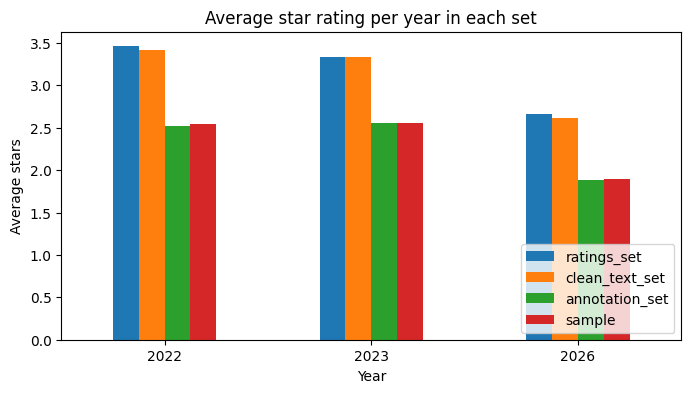

In [70]:
mean_rating_all.plot(kind='bar', figsize=(8, 4))
plt.title('Average star rating per year in each set')
plt.xlabel('Year')
plt.ylabel('Average stars')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [71]:
star_pct_all = pd.DataFrame({
    'ratings_set': df_ratings['score'].value_counts(normalize=True),
    'clean_text_set': df_clean_full['score'].value_counts(normalize=True),
    'annotation_set': df_annotate_unique['score'].value_counts(normalize=True),
    'sample': df_sample['score'].value_counts(normalize=True)}).sort_index().mul(100).round(1)
star_pct_all

,ratings_set,clean_text_set,annotation_set,sample
score,,,,
1,31.9,32.4,48.8,51.1
2,6.9,7.1,11.6,11.8
3,7.1,7.2,10.1,9.0
4,9.7,9.8,9.2,9.0
5,44.5,43.6,20.3,19.1


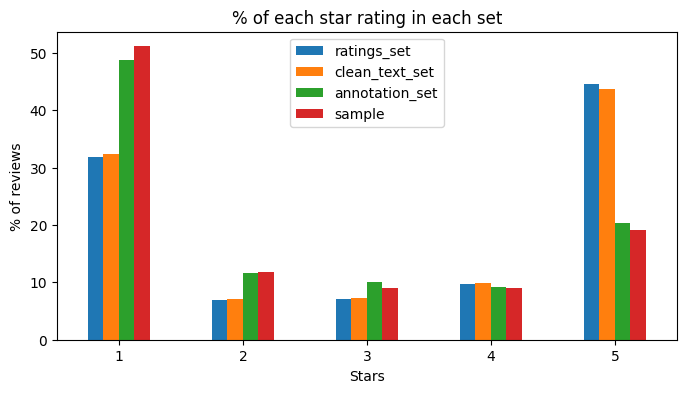

In [72]:
star_pct_all.plot(kind='bar', figsize=(8, 4))
plt.title('% of each star rating in each set')
plt.xlabel('Stars')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.show()

In [73]:
star_counts_all = pd.concat({
    'ratings_set': pd.crosstab(df_ratings['year'], df_ratings['score']).stack(),
    'clean_text_set': pd.crosstab(df_clean_full['year'], df_clean_full['score']).stack(),
    'annotation_set': pd.crosstab(df_annotate_unique['year'], df_annotate_unique['score']).stack()}, axis=1)
star_counts_all

ratings_set  clean_text_set  annotation_set
year score                                             
2022 1            23204           21113           13787
     2             4974            4639            3296
     3             5444            4958            3006
     4             8505            7693            2983
     5            40202           35118            6749
2023 1            19080           17201           11478
     2             4646            4243            3139
     3             4854            4407            2923
     4             6611            6000            2737
     5            28844           25688            5919
2026 1            13563           12769            8809
     2             2396            2287            1651
     3             2080            1943            1155
     4             1882            1744             736
     5             8881            7943            1496

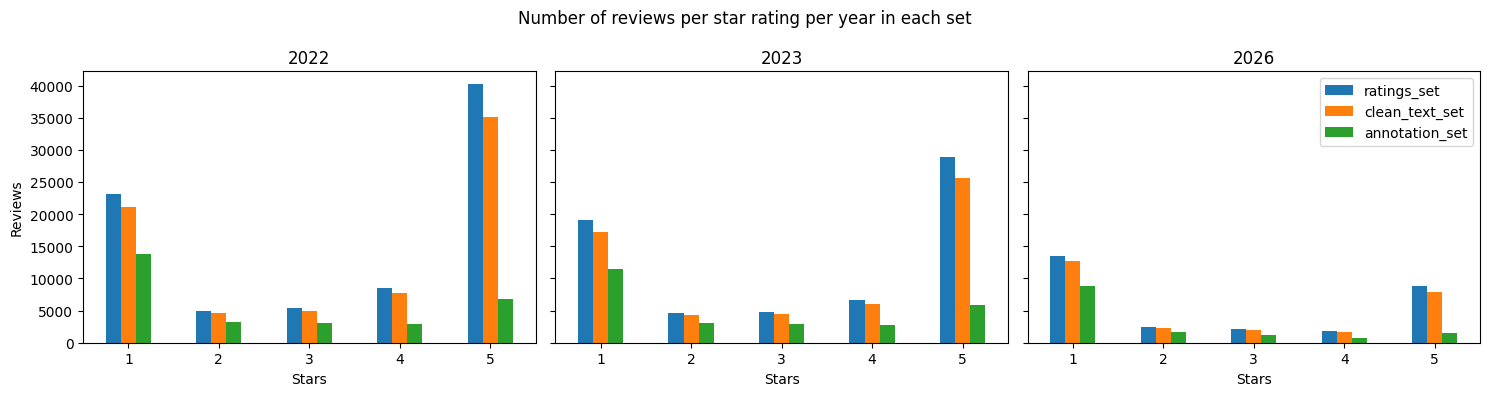

In [74]:
years = star_counts_all.index.get_level_values('year').unique()
fig, axes = plt.subplots(1, len(years), figsize=(15, 4), sharey=True)

for ax, year in zip(axes, years):
    star_counts_all.loc[year].plot(kind='bar', ax=ax, legend=False)
    ax.set_title(str(year))
    ax.set_xlabel('Stars')
    ax.tick_params(axis='x', rotation=0)

axes[0].set_ylabel('Reviews')
axes[-1].legend()
fig.suptitle('Number of reviews per star rating per year in each set')
plt.tight_layout()
plt.show()